# Play with AGS Provider

本文档是 AGS template/raw runtime 的底层接口实验，保留历史输出，不执行 OSWorld benchmark 的 setup/evaluator。当前 OSWorld-V1 六模式使用 AGS control_plane + nexus interface 与 COS task_files，见 ../osworld-runbook.md。

## 初始化环境

导入日志、Provider，以及 Notebook 里展示截图要用到的模块。

In [1]:
import json

from IPython.display import Image, display

from nexus.utils.log import setup_logging
from nexus.runtime import AGSRuntimeProvider

setup_logging()

## 创建 Runtime Provider

这里直接把模板模式所需的配置写死在 Notebook 里，不从外部文件读取。 只要把 `AGS_API_KEY` 替换成你自己的 key，就可以直接运行。

In [2]:
AGS_API_KEY = "__AGS_API_KEY__"
AGS_TEMPLATE = "osworld-2qjpqxjq08c"
AGS_DOMAIN = "ap-guangzhou.tencentags.com"

rp = AGSRuntimeProvider(
    api_key=AGS_API_KEY,
    template=AGS_TEMPLATE,
    domain=AGS_DOMAIN,
    interface_mode="raw",
    request_timeout=180.0,
    instance_ready_timeout=300.0,
)

## 获取 AGS Raw OSWorld Runtime

在 `acquire()` 时显式指定 `runtime_kind='osworld'`、`launch_mode='native'` 和 `interface_mode='raw'`，这样拿到的就是 `AGSRawOSWorldRuntime`，不会被转换成裁剪后的 Nexus-style executor 接口。

In [3]:
runtime = await rp.acquire(
    name="main",
    runtime_kind="osworld",
    launch_mode="native",
    interface_mode="raw",
)

print(type(runtime).__name__)
print(json.dumps(runtime.get_metadata()["handle"], ensure_ascii=False, indent=2))

2026-03-18 19:28:59 | INFO | nexus.runtime.providers.ags | AGS template create payload={'template': 'osworld-2qjpqxjq08c', 'timeout': 1800, 'api_key': '***REDACTED***', 'domain': 'ap-guangzhou.tencentags.com', 'request_timeout': 180.0}


2026-03-18 19:28:59 | INFO | e2b.api | Request POST https://api.ap-guangzhou.tencentags.com/sandboxes


2026-03-18 19:28:59 | INFO | e2b.api.client_sync | Request: POST https://api.ap-guangzhou.tencentags.com/sandboxes


2026-03-18 19:28:59 | INFO | e2b.api.client_sync | Response: 201 https://api.ap-guangzhou.tencentags.com/sandboxes


2026-03-18 19:28:59 | INFO | e2b.api | Response 201


2026-03-18 19:29:00 | INFO | nexus.runtime.providers.ags | AGS template runtime main ready: instance_id=608d82a4e3854b50af4c5f7b9e189d9eb120bf7c template=osworld-2qjpqxjq08c


AGSRawOSWorldRuntime
{
  "instance_id": "608d82a4e3854b50af4c5f7b9e189d9eb120bf7c",
  "domain": "ap-guangzhou.tencentags.com",
  "tool_id": null,
  "tool_name": "osworld-2qjpqxjq08c",
  "tool_type": "custom",
  "metadata": {
    "provision_mode": "template",
    "template": "osworld-2qjpqxjq08c"
  }
}


## 查看原始端点

`AGSRawOSWorldRuntime` 会把 OSWorld server、本地 Chromium CDP、VNC、VLC 这些原始入口都暴露出来，方便继续兼容原版 OSWorld agent 栈或调试工具。

In [ ]:
{
    "server_url": runtime.server_url,
    "chromium_url": runtime.chromium_url,
    "chromium_cdp_url": await runtime.chromium_cdp_url(),
    "vnc_url": runtime.vnc_url,
    "vlc_url": runtime.vlc_url,
}

## 截图和屏幕信息

先走一遍最基础的观测接口：`screen_size()` 和 `screenshot()`。

{'height': 1080, 'width': 1920}


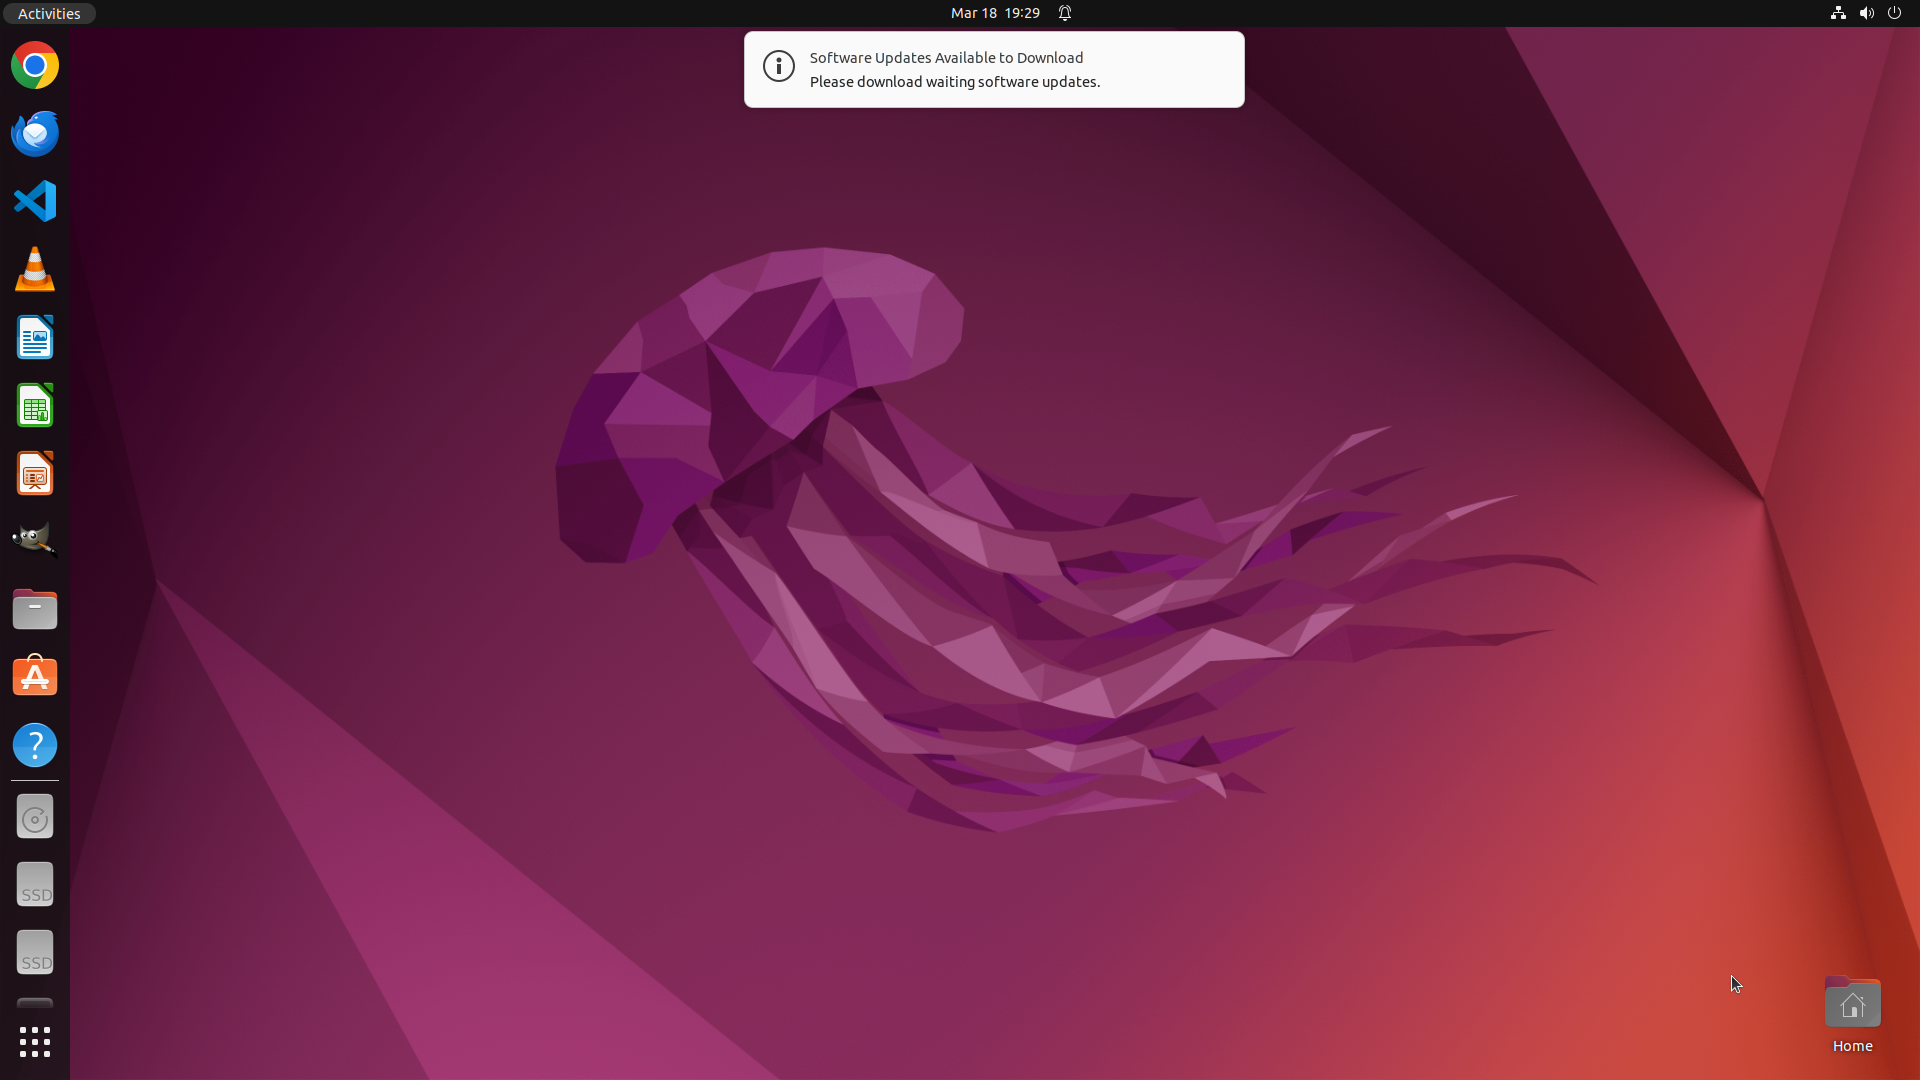

In [5]:
screen_size = await runtime.screen_size()
screenshot_bytes = await runtime.screenshot()

print(screen_size)
display(Image(screenshot_bytes))

## 执行命令

`AGSRawOSWorldRuntime.execute()` 会直接打到原始 `/execute` 端点。 这里分别演示 shell 命令和 Python 代码两种最常见的交互方式。

In [6]:
execute_result = await runtime.execute("printf 'hello from shell\\n' && pwd", shell=True)
execute_result

{'error': '',
 'output': 'hello from shell\n/home/user\n',
 'returncode': 0,
 'status': 'success'}

In [7]:
python_result = await runtime.run_python("import platform\nprint(platform.platform())")
python_result

{'error': '',
 'message': 'Linux-5.4.119-19-0009-03_2.0.1-00030-gfd357c61b1db-x86_64-with-glibc2.35\n',
 'need_more': False,
 'output': 'Linux-5.4.119-19-0009-03_2.0.1-00030-gfd357c61b1db-x86_64-with-glibc2.35\n',
 'return_code': 0,
 'status': 'success'}

## 读取可访问性树和终端输出

`accessibility_tree()` 返回的是原始 OSWorld accessibility payload。 如果当前没有活动终端，`terminal_output()` 也会如实返回空值。

In [8]:
terminal_output = await runtime.terminal_output()
a11y = await runtime.accessibility_tree()

print("terminal_output =", terminal_output)
print("accessibility keys =", list(a11y.keys()) if isinstance(a11y, dict) else type(a11y).__name__)

a11y["AT"][:1000] if isinstance(a11y, dict) and "AT" in a11y else a11y

terminal_output = {'output': None, 'status': 'success'}
accessibility keys = ['AT']


'<desktop-frame xmlns:st="https://accessibility.ubuntu.example.org/ns/state" xmlns:attr="https://accessibility.ubuntu.example.org/ns/attributes" xmlns:cp="https://accessibility.ubuntu.example.org/ns/component" xmlns:doc="https://accessibility.ubuntu.example.org/ns/document" xmlns:docattr="https://accessibility.ubuntu.example.org/ns/document/attributes" xmlns:txt="https://accessibility.ubuntu.example.org/ns/text" xmlns:val="https://accessibility.ubuntu.example.org/ns/value" xmlns:act="https://accessibility.ubuntu.example.org/ns/action"><application name="gsd-keyboard"/><application name="xdg-desktop-portal-gtk"/><application name="gsd-wacom"/><application name="evolution-alarm-notify"/><application name="gsd-color"/><application name="ibus-extension-gtk3"/><application name="gsd-power"/><application name="ibus-x11"/><application name="gsd-xsettings"/><application name="gsd-media-keys"/><application name="org.gnome.Software"/><application name="gjs"><frame name="@!0,0;BDHF" st:enabled="t

## 一个已知现象

当前这个模板上的 `/run_bash_script` 端点会返回服务端 `_append_event` 错误，所以本 Notebook 不把 `runtime.run_bash_script()` 放进主流程里。 方法本身已经通过 `AGSRawOSWorldRuntime` 暴露出来，等模板侧修复后可以直接调用。

## 释放 Runtime

模板模式同样通过 `release_all()` 统一回收实例。

In [9]:
await rp.release_all()

2026-03-18 19:29:03 | INFO | e2b.api | Request DELETE https://api.ap-guangzhou.tencentags.com/sandboxes/608d82a4e3854b50af4c5f7b9e189d9eb120bf7c


2026-03-18 19:29:03 | INFO | e2b.api.client_sync | Request: DELETE https://api.ap-guangzhou.tencentags.com/sandboxes/608d82a4e3854b50af4c5f7b9e189d9eb120bf7c


2026-03-18 19:29:04 | INFO | e2b.api.client_sync | Response: 204 https://api.ap-guangzhou.tencentags.com/sandboxes/608d82a4e3854b50af4c5f7b9e189d9eb120bf7c


2026-03-18 19:29:04 | INFO | e2b.api | Response 204


2026-03-18 19:29:04 | INFO | nexus.runtime.providers.ags | Released AGS template runtime main
